# Employee Performance & HR Analytics Dashboard

**Course:** Data Handling, Visualization & Feature Engineering (AML001) | **Capstone Project 3**

**Question this dashboard answers:** How do salary, experience and performance relate across departments?

**Pipeline:** Explore → Analyze → Visualize → Layout → Story

## 1. Import libraries and create the dataset

In [1]:
# Install Plotly (run if not already installed)
!pip install plotly -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# Create a 30-employee dataset
data = {
    "Employee_ID": ['E101', 'E102', 'E103', 'E104', 'E105', 'E106', 'E107', 'E108', 'E109', 'E110', 'E111', 'E112', 'E113', 'E114', 'E115', 'E116', 'E117', 'E118', 'E119', 'E120', 'E121', 'E122', 'E123', 'E124', 'E125', 'E126', 'E127', 'E128', 'E129', 'E130'],
    "Name": ['Aarav', 'Priya', 'Rohan', 'Sneha', 'Karan', 'Anjali', 'Vikram', 'Neha', 'Arjun', 'Pooja', 'Rahul', 'Divya', 'Amit', 'Kavya', 'Sanjay', 'Meera', 'Nikhil', 'Isha', 'Manish', 'Ritu', 'Deepak', 'Simran', 'Varun', 'Tanvi', 'Harsh', 'Nisha', 'Gaurav', 'Swati', 'Yash', 'Komal'],
    "Department": ['Finance', 'IT', 'Marketing', 'Finance', 'Marketing', 'Operations', 'Marketing', 'Operations', 'Finance', 'IT', 'Operations', 'HR', 'IT', 'Marketing', 'HR', 'Finance', 'HR', 'Finance', 'IT', 'Marketing', 'HR', 'HR', 'Marketing', 'Operations', 'IT', 'Finance', 'IT', 'Operations', 'Operations', 'HR'],
    "Experience_Years": [3.0, 5.1, 6.1, 7.4, 12.0, 3.8, 8.2, 9.3, 1.7, 9.5, 3.4, 1.9, 14.3, 14.5, 12.3, 5.3, 2.4, 10.6, 7.2, 2.7, 7.9, 1.5, 13.7, 4.6, 10.3, 5.4, 8.3, 8.7, 3.6, 14.6],
    "Salary": [46500, 60000, 47500, 53500, 73500, 38000, 53000, 54000, 37000, 71000, 41000, 39500, 89500, 81500, 68500, 50500, 31500, 74500, 62500, 39000, 60000, 31000, 79000, 44000, 69000, 53000, 70500, 59000, 45500, 78000],
    "Performance_Score": [4.4, 2.6, 2.9, 3.3, 3.1, 3.4, 3.8, 3.5, 2.3, 2.8, 2.4, 3.0, 4.0, 3.9, 4.1, 3.6, 2.8, 3.8, 3.9, 2.8, 3.2, 2.9, 3.9, 2.8, 4.3, 2.9, 2.1, 3.6, 2.6, 4.0],
    "Joining_Date": pd.to_datetime(['2023-01-02', '2020-11-27', '2019-11-28', '2018-08-10', '2014-01-04', '2022-03-16', '2017-10-23', '2016-09-16', '2024-04-21', '2016-07-05', '2022-08-09', '2024-02-08', '2011-09-18', '2011-07-07', '2013-09-17', '2020-09-15', '2023-08-09', '2015-05-30', '2018-10-22', '2023-04-22', '2018-02-09', '2024-07-03', '2012-04-24', '2021-05-29', '2015-09-17', '2020-08-09', '2017-09-16', '2017-04-23', '2022-05-28', '2011-05-31'])
}

df = pd.DataFrame(data)

# Display raw dataset
display(df)

,Employee_ID,Name,Department,Experience_Years,Salary,Performance_Score,Joining_Date
0,E101,Aarav,Finance,3.0,46500,4.4,2023-01-02
1,E102,Priya,IT,5.1,60000,2.6,2020-11-27
2,E103,Rohan,Marketing,6.1,47500,2.9,2019-11-28
3,E104,Sneha,Finance,7.4,53500,3.3,2018-08-10
4,E105,Karan,Marketing,12.0,73500,3.1,2014-01-04
5,E106,Anjali,Operations,3.8,38000,3.4,2022-03-16
6,E107,Vikram,Marketing,8.2,53000,3.8,2017-10-23
7,E108,Neha,Operations,9.3,54000,3.5,2016-09-16
8,E109,Arjun,Finance,1.7,37000,2.3,2024-04-21
9,E110,Pooja,IT,9.5,71000,2.8,2016-07-05


**Dataset note:** this is a sample dataset created for this exercise (30 employees, 5 departments). Salary is in rupees (₹) per month, Performance_Score is on a 1-5 scale, and Experience_Years is the length of service.

## 2. Explore and inspect the dataset

In [2]:
# 1. Number of rows and columns
print("Dataset Shape:")
print(df.shape)

# 2. Column names and data types
print("\nDataset Information:")
df.info()

# 3. Statistical summary of numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

# 4. Frequency distribution of the categorical column
print("\nDepartment-wise Employee Count:")
print(df["Department"].value_counts())

Dataset Shape:
(30, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Employee_ID        30 non-null     object        
 1   Name               30 non-null     object        
 2   Department         30 non-null     object        
 3   Experience_Years   30 non-null     float64       
 4   Salary             30 non-null     int64         
 5   Performance_Score  30 non-null     float64       
 6   Joining_Date       30 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 1.8+ KB

Descriptive Statistics:


,Experience_Years,Salary,Performance_Score,Joining_Date
count,30.000000,30.000000,30.000000,30
mean,7.310000,56700.000000,3.290000,2018-09-12 04:48:00
min,1.500000,31000.000000,2.100000,2011-05-31 00:00:00
25%,3.650000,44375.000000,2.800000,2015-11-29 00:00:00
50%,7.300000,53750.000000,3.250000,2018-09-15 12:00:00
75%,10.100000,70125.000000,3.875000,2022-05-09 18:00:00
max,14.600000,89500.000000,4.400000,2024-07-03 00:00:00
std,4.132324,16011.633702,0.629367,NaN



Department-wise Employee Count:
Department
Finance       6
IT            6
Marketing     6
Operations    6
HR            6
Name: count, dtype: int64


**Observations**

- The dataset has 30 employees and 7 columns.
- Experience_Years, Salary and Performance_Score are numerical; Department is categorical; Joining_Date is a date column.
- There are no missing values, and each of the 5 departments has 6 employees, so no department dominates the data.
- Salary ranges from ₹31,000 to ₹89,500 (mean about ₹56,700); Performance_Score ranges from 2.1 to 4.4 (mean about 3.29).

## 3. Correlation analysis

Correlation Matrix:


,Experience_Years,Salary,Performance_Score
Experience_Years,1.00,0.94,0.58
Salary,0.94,1.00,0.49
Performance_Score,0.58,0.49,1.00


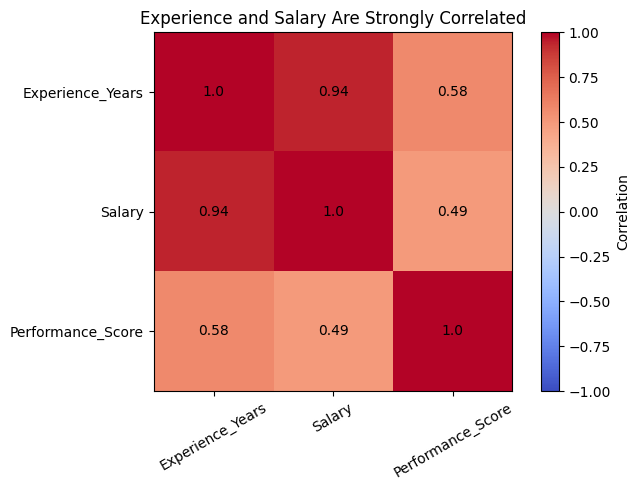

In [3]:
# Correlation between the numerical variables
correlation = df[["Experience_Years", "Salary", "Performance_Score"]].corr()
print("Correlation Matrix:")
display(correlation.round(2))

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=30)
plt.yticks(range(len(correlation.columns)), correlation.columns)

# Write each correlation value inside its cell
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, round(correlation.iloc[i, j], 2), ha="center", va="center")

plt.title("Experience and Salary Are Strongly Correlated")
plt.tight_layout()
plt.show()

**Interpretation**

- Experience and Salary have a very strong positive correlation (about **0.94**): employees with more years of service earn more.
- Experience and Performance_Score have a moderate positive correlation (about 0.58), and Salary and Performance_Score about 0.49.
- Correlation shows that two variables move together; it does **not** prove that one causes the other.

## 4. Groupby analysis

In [4]:
# Group employees by department
dept_summary = df.groupby("Department").agg(
    Average_Salary=("Salary", "mean"),
    Average_Experience=("Experience_Years", "mean"),
    Average_Performance=("Performance_Score", "mean"),
    Employee_Count=("Employee_ID", "count")
).round(2)

print("Department-wise Summary:")
display(dept_summary)

Department-wise Summary:


,Average_Salary,Average_Experience,Average_Performance,Employee_Count
Department,,,,
Finance,52500.00,5.57,3.38,6
HR,51416.67,6.77,3.33,6
IT,70416.67,9.12,3.28,6
Marketing,62250.00,9.53,3.40,6
Operations,46916.67,5.57,3.05,6


**Interpretation**

- IT has the highest average salary (about ₹70,400) and Operations the lowest (about ₹46,900).
- Operations also has the lowest average performance score (about 3.05); the other four departments are close together (about 3.3-3.4).
- IT employees have higher average experience than Finance, HR and Operations, so part of IT's salary lead may reflect experience and not department alone.

## 5. Interactive dashboard using Plotly

The dashboard has four chart types:

1. **Scatter plot:** Experience vs Salary, coloured by department (top-left, the most important chart)
2. **Bar chart:** Average salary by department
3. **Histogram:** Distribution of performance scores
4. **Line chart:** Salary of employees in order of joining date

Each department keeps the **same colour in every chart**, and every title states the finding.

In [5]:
# One fixed colour per department, used in every chart
colors = {
    "IT": "#636EFA", "HR": "#EF553B", "Finance": "#00CC96",
    "Marketing": "#AB63FA", "Operations": "#FFA15A"
}

# Prepare data for the bar chart and the line chart
dept_salary = (df.groupby("Department")["Salary"].mean()
                 .sort_values(ascending=False).reset_index())
by_date = df.sort_values("Joining_Date")      # always sort before a time-ordered line

# Create a 2x2 dashboard
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Salary Rises Strongly With Experience",
        "IT Has the Highest Average Salary, Operations the Lowest",
        "Most Employees Score Between 2.5 and 4.0 on Performance",
        "Employees Who Joined Earlier Earn Higher Salaries"
    ),
    vertical_spacing=0.17,
    horizontal_spacing=0.12
)

# CHART 1: Scatter plot (top-left), one trace per department so the legend can toggle them
for d in df["Department"].unique():
    sub = df[df["Department"] == d]
    fig.add_trace(
        go.Scatter(
            x=sub["Experience_Years"],
            y=sub["Salary"],
            mode="markers",
            name=d,
            marker=dict(size=11, color=colors[d]),
            customdata=sub[["Name", "Performance_Score"]],
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>" +
                "Experience: %{x} years<br>" +
                "Salary: ₹%{y:,.0f}<br>" +
                "Performance: %{customdata[1]}<extra>" + d + "</extra>"
            )
        ),
        row=1, col=1
    )

# CHART 2: Bar chart (top-right)
fig.add_trace(
    go.Bar(
        x=dept_salary["Department"],
        y=dept_salary["Salary"],
        marker_color=[colors[d] for d in dept_salary["Department"]],
        text=dept_salary["Salary"].round(0),
        texttemplate="₹%{text:,.0f}",
        textposition="outside",
        showlegend=False,
        hovertemplate="Department: %{x}<br>Average Salary: ₹%{y:,.0f}<extra></extra>"
    ),
    row=1, col=2
)

# CHART 3: Histogram (bottom-left)
fig.add_trace(
    go.Histogram(
        x=df["Performance_Score"],
        nbinsx=6,
        marker_color="#7F8C8D",
        showlegend=False,
        hovertemplate="Score range: %{x}<br>Employees: %{y}<extra></extra>"
    ),
    row=2, col=1
)

# CHART 4: Line chart (bottom-right)
fig.add_trace(
    go.Scatter(
        x=by_date["Joining_Date"],
        y=by_date["Salary"],
        mode="lines+markers",
        marker=dict(size=7, color="#7F8C8D"),
        line=dict(color="#7F8C8D"),
        showlegend=False,
        hovertemplate="Joined: %{x|%d %b %Y}<br>Salary: ₹%{y:,.0f}<extra></extra>"
    ),
    row=2, col=2
)

# Axis labels
fig.update_xaxes(title_text="Experience (years)", row=1, col=1)
fig.update_yaxes(title_text="Salary (₹ per month)", row=1, col=1)
fig.update_xaxes(title_text="Department", row=1, col=2)
fig.update_yaxes(title_text="Average Salary (₹)", range=[0, 85000], row=1, col=2)   # bars start at zero
fig.update_xaxes(title_text="Performance Score (1-5)", row=2, col=1)
fig.update_yaxes(title_text="Number of Employees", row=2, col=1)
fig.update_xaxes(title_text="Joining Date", row=2, col=2)
fig.update_yaxes(title_text="Salary (₹ per month)", row=2, col=2)

# Dashboard title and layout
fig.update_layout(
    title=dict(text="EMPLOYEE PERFORMANCE & HR ANALYTICS DASHBOARD",
               x=0.5, font=dict(size=22)),
    height=850,
    width=1200,
    template="plotly_white",
    legend_title_text="Department",
    hovermode="closest"
)

# Display the interactive dashboard
fig.show()

**Dashboard features:** hover over any point or bar to see exact values, drag to zoom, and click a department in the legend to hide or show it in the scatter plot (double-click a department to isolate it).

## 6. Export the interactive dashboard

In [6]:
# Save the complete dashboard as a standalone HTML file
fig.write_html("HR_Analytics_Dashboard.html", include_plotlyjs=True)
print("Dashboard exported successfully!")

Dashboard exported successfully!


To download the HTML file in Google Colab, run the next cell:

In [7]:
from google.colab import files
files.download("HR_Analytics_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Dashboard reflection

The Employee Performance and HR Analytics Dashboard presents the salary, experience and performance scores of 30 employees across five departments. The scatter plot shows that salary rises strongly with experience (a correlation of about 0.94), while performance score is only moderately related to experience (about 0.58). The bar chart shows that IT has the highest average salary (about ₹70,400) and Operations the lowest (about ₹46,900), although IT employees also have more average experience than Finance, HR and Operations, so part of that gap may reflect experience rather than department alone. The histogram shows that 24 of the 30 employees score between 2.5 and 4.0, and the line chart shows that employees who joined earlier earn higher salaries, which is the same experience-and-pay relationship seen from a time view, since experience is measured from the joining date. Overall, the dashboard suggests that pay in this dataset is driven mainly by length of service, with department differences playing a smaller role. However, the dataset contains only 30 records, was created for this exercise, and correlation does not prove causation, so these findings should not be generalised to a real organisation.